## Wstęp do Uczenia Maszynowego

#### Laboratorium 01



### Zakres laboratorium

- organizacja przedmiotu i podstawy pracy w Pythonie
- eksploracyjna analiza danych
- drzewa regresyjne i predykcja
- błąd średniokwadratowy (MSE)


### 0\. Sprawy organizacyjne

Kontakt: MS Teams

Lub mailowo: anna.kozak@pw.edu.pl, katarzyna.woznica@pw.edu.pl, krzyzinskimateusz23@gmail.com

Pracujemy z językiem `Python`.

Pracujemy z repozytorium GitHub: [https://github.com/kozaka93/2026Z-MachineLearning](https://github.com/kozaka93/2026Z-MachineLearning)

Na repozytorium będą się pojawiały pliki `.ipynb` z materiałami na zajęcia.

Rozwiązania kolejnych etapów projektu przesyłamy poprzez *Zadanie* w MS Teams w wyznaczonym terminie.


*Zasady zaliczenia (suma 140p):*

- Zajęcia laboratoryjne (80p):
  - projekt I (12p + 12p + 28p)
  - projekt II (16p)
  - niezapowiedziane wejściówki (12p = 3 x 4p)

- Egzamin (60p)

> Warunkiem koniecznym do dopuszczenia do egzaminu końcowego jest pomyślne ukończenie zajęć laboratoryjnych, czyli uzyskanie powyżej **50% punktów** możliwych do zdobycia.

> Warunkiem koniecznym do uzyskania pozytywnej oceny z przedmiotu jest zdobycie ponad **50% punktów** możliwych do uzyskania z egzaminu pisemnego.

Ocena końcowa ustalana jest na podstawie sumy punktów uzyskanych z zajęć laboratoryjnych oraz egzaminu pisemnego, według poniższego przelicznika:

| Ocena |  3 | 3.5 | 4 | 4.5 | 5 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| Punkty   | (70, 84] | (84, 98] | (98, 112] | (112, 126] | (126, ∞) |

-----

### 1\. Czym będziemy się zajmować?

<img src="tematy.png" alt="drawing" width="800">

W uczeniu maszynowym pracujemy ze zbiorem danych $\mathbf{D}= (X, Y)$.

  - $X$ to **macierz cech** (zmiennych niezależnych) o wymiarze $n \times p$ ($n$ próbek, $p$ cech).
  - $Y$ to **wektor zmiennej docelowej** (etykieta, wynik, który chcemy przewidzieć) o wymiarze $n$.

#### Rodzaje Uczenia Maszynowego

1.  **Uczenie nadzorowane (Supervised Learning):** Jeżeli wartość $Y$ jest znana w zbiorze treningowym (czyli mamy dane wejściowe **i** poprawne odpowiedzi). Chcemy, aby model nauczył się mapowania $X \rightarrow Y$.
      * **Regresja (Regression):** Gdy zmienna $Y$ jest ciągła (np. zarobki, temperatura, cena domu, czyli $Y \in R$).
      * **Klasyfikacja (Classification):** Gdy zmienna $Y$ jest dyskretna (kategorie, klasy, np. tak/nie, kot/pies/mysz, czyli $Y \in \{0, 1, 2, ..\}$). Gdy $Y \in \{0,1\}$ mówimy o klasyfikacji binarnej.
2.  **Uczenie nienadzorowane (Unsupervised Learning):** Jeżeli nie znamy wartości $Y$ (brakuje nam etykiet). Celem jest znalezienie ukrytych wzorców i struktury w samych danych $X$ (np. grupowanie danych w skupienia).

-----

### 2\. Jak wygląda proces uczenia?

Proces uczenia maszynowego polega na stworzeniu **modelu** $\mathbf{M}$, który na podstawie danych wejściowych $X$ potrafi przewidzieć wartość docelową $\hat{Y}$.

**Model:** $\mathbf{M}: D \rightarrow \hat{Y}$

**Prognoza:** $\hat{Y} = M(X)$ .

Model jest "uczony" na danych $D$, aby jak najlepiej minimalizować błąd między przewidywanym $\hat{Y}$ a rzeczywistym $Y$.

-----

### 3\. Etapy uczenia maszynowego

#### 3.1 Pakiety i dane



In [2]:
# Import potrzebnych pakietów (bibliotek)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 'sklearn' (scikit-learn)  biblioteka do uczenia maszynowego w Pythonie.
# Z niej importujemy konkretne algorytmy, np. 'tree' (Drzewa Decyzyjne).
from sklearn import tree

# Będziemy też potrzebować funkcji do podziału danych
from sklearn.model_selection import train_test_split

# Metryka do oceny modelu (np. błąd średniokwadratowy)
from sklearn.metrics import mean_squared_error

> Zaleca się importowanie tylko konkretnych komponentów, między innymi dlatego, że:
- nasz skrypt będzie miał szybszy start
- oszczędamy pamięć RAM
- mamy czytelny kod
- mamy porządek w nazwach i brak konfliktów
- edytory (VS Code, PyCharm) szybciej i celniej będą podpowiadać składnię
- łatwiej wykryjemy "martwy" kod (nieużywany import będzie podświetlony)

Rozważmy zbiór danych zawierający informacje o zarobkach zawodników baseballu.

In [4]:
# Zbiory danych można wczytać przez link z GitHub, nie ma konieczności ich pobierania.
# index_col =[0] mówi, aby pierwszą kolumnę pliku CSV potraktować jako indeks wierszy.
Hitters = pd.read_csv('Hitters.csv', index_col =[0])

-----

#### 3.2 Przygotowanie danych (Pre-processing)

##### *Zadanie 1*

Przygotuj zbiór danych do zbudowania pierwszego modelu.

a) Utwórz zbiór *Hitters\_small* zawierający zmienne o nazwach *Years, Hits, Salary*.

b) Przyjrzyj się utworzonemu zbiorowi danych. Jaki jest wymiar danych, typy zmiennych, czy są braki danych? Jakie rozkłady mają zmienne?

c) Podziel zbiór danych na X = ['Years', 'Hits'] (cechy) i y = ['Salary'] (zmienna docelowa).

d) Podziel dane na zbiór treningowy i testowy (proporcja 50:50).

**Rozwiązanie Zadania 1**

In [ ]:
Hitters_small = Hitters[['Years', 'Hits', 'Salary']]

(322, 3)

In [ ]:
Hitters_small.shape

<bound method DataFrame.isna of      Years  Hits  Salary
0        1    66     NaN
1       14    81   475.0
2        3   130   480.0
3       11   141   500.0
4        2    87    91.5
..     ...   ...     ...
317      5   127   700.0
318     12   136   875.0
319      6   126   385.0
320      8   144   960.0
321     11   170  1000.0

[322 rows x 3 columns]>

In [29]:
Hitters_small.describe()

,Years,Hits,Salary
count,322.000000,322.000000,263.000000
mean,7.444099,101.024845,535.925882
std,4.926087,46.454741,451.118681
min,1.000000,1.000000,67.500000
25%,4.000000,64.000000,190.000000
50%,6.000000,96.000000,425.000000
75%,11.000000,137.000000,750.000000
max,24.000000,238.000000,2460.000000


In [ ]:
Hitters_small.head

<bound method NDFrame.head of      Years  Hits  Salary
0        1    66     NaN
1       14    81   475.0
2        3   130   480.0
3       11   141   500.0
4        2    87    91.5
..     ...   ...     ...
317      5   127   700.0
318     12   136   875.0
319      6   126   385.0
320      8   144   960.0
321     11   170  1000.0

[322 rows x 3 columns]>

In [13]:
Hitters_small.dtypes

Years       int64
Hits        int64
Salary    float64
dtype: object

In [21]:
any(np.isnan(Hitters_small))

True

(array([76., 66., 51., 45., 24., 25., 23.,  8.,  2.,  2.]),
 array([ 1. ,  3.3,  5.6,  7.9, 10.2, 12.5, 14.8, 17.1, 19.4, 21.7, 24. ]),
 <BarContainer object of 10 artists>)

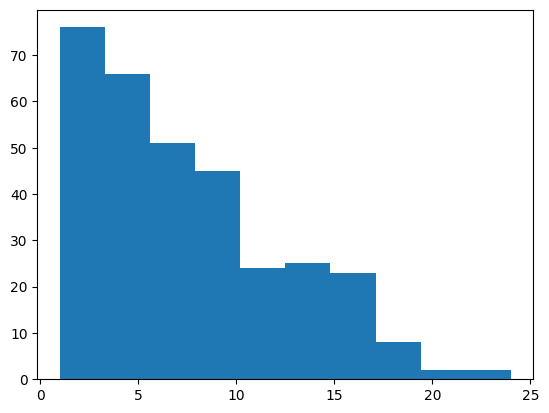

In [ ]:
plt.hist(Hitters_small[['Years']])

(array([ 7., 33., 64., 55., 50., 46., 37., 20.,  8.,  2.]),
 array([  1. ,  24.7,  48.4,  72.1,  95.8, 119.5, 143.2, 166.9, 190.6,
        214.3, 238. ]),
 <BarContainer object of 10 artists>)

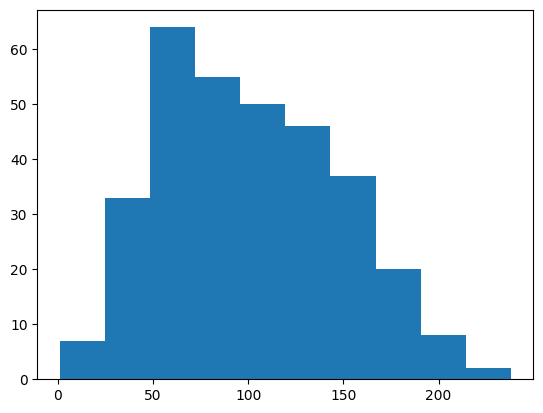

In [27]:
plt.hist(Hitters_small[['Hits']])

(array([108.,  50.,  49.,  27.,  11.,   7.,   2.,   6.,   1.,   2.]),
 array([  67.5 ,  306.75,  546.  ,  785.25, 1024.5 , 1263.75, 1503.  ,
        1742.25, 1981.5 , 2220.75, 2460.  ]),
 <BarContainer object of 10 artists>)

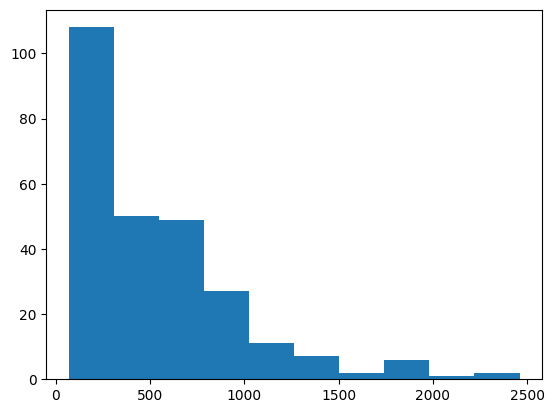

In [26]:
plt.hist(Hitters_small[['Salary']])

In [28]:
Hitters_small.dropna

X = Hitters_small[['Years', 'Hits']]
Y = Hitters_small[['Salary']]



In [ ]:
## Eksperyment - transformacja log zmiennych skośnych

experiment = pd.DataFrame({"Var1" : Hitters.Salary,
                           # stała większa od maksimum, żeby argument logarytmu był dodatni
                           "Var2": Hitters.Salary.max() + 1 - Hitters.Salary})

experiment["log(Var1)"] = np.log(experiment.Var1)
experiment["log(Var2)"] = np.log(experiment.Var2)

experiment.hist()
plt.show()

In [ ]:
rand = np.random.uniform(1, 322/2)

#### 3.3 Podstawy drzew decyzyjnych 

#### *Jak się buduje drzewa dla zadania regresji?*
1. Dzielimy przestrzeń $X = (X_1, X_2, \dots, X_p)$ na $J$ regionów $R_1, R_2, \dots, R_J$.
2. Predykcja w $j$-tym regionie jest równa średniej wartości obserwacji $y$ ze zbioru treningowego znajdujących się w regionie $R_j$. 

In [ ]:
# Tworzymy obiekt klasy DecisionTreeRegressor.
# Drzewo będzie miało domyślne parametry.
Tree = tree.DecisionTreeRegressor()

# Trening (uczenie) modelu: Używamy metody .fit(), aby nauczyć model na danych treningowych.
Tree.fit()

Wizualizacja drzewa decyzyjnego

In [ ]:
tree.plot_tree(Tree,
               feature_names=X.columns.tolist(), # Nazwy kolumn cech
               filled=True # Wypełnienie węzłów kolorem
               ) 
plt.title("Drzewo Decyzyjne")
plt.show()

Przejrzysty zapis otrzymanego drzewa

In [ ]:
from sklearn.tree import export_text
t = export_text(Tree)
print(t)

**Drzewo o trzech liściach**

Poprzez dobór hiperparametrów możemy wpływać na złożoność i jakość modelu drzewa. Zbudujmy drzewo z hiperparametrem `max_leaf_nodes = 3`.

In [ ]:
Tree3 = tree.DecisionTreeRegressor()
Tree3 = Tree3.fit()

tree.plot_tree(Tree3, 
               feature_names=Tree3.feature_names_in_.tolist(),
               filled=True)
plt.show()

#### 3.4 Jak dobry jest nasz model (zadanie regresji)?

Błąd średniokwadratowy:

$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{f}(x_i))^2$,

gdzie:

$y_i$ - wartość prawdziwa dla $i$-tej obserwacji,

$\hat{f}(x_i)$ jest predykcją modelu dla $i$-tej obserwacji.

In [ ]:
# Generowanie prognoz (Prediction)
# Używamy wytrenowanych modeli do przewidywania wartości 'Salary' na nieznanych danych (X_test).


# Obliczanie Błędu Średniokwadratowego (Mean Squared Error - MSE)

